# 01 · Datos y bases (semilla 42)

Parte 1 de 3 del `02_DS02_ensemble_RUL.ipynb` original. Mismo código, mismo orden.

**Corre de arriba abajo.** Tarda la primera parte lenta (`run_seed` semilla 42). Al final guarda en `artifacts/` lo que necesitan los cuadernos 02 y 03.

Orden: `01` → `02` → `03`.

# 02. N-CMAPSS DS02 — Ensamble de stacking híbrido (protocolo honesto)

**Qué predecimos.** La vida útil restante (RUL) de un motor turbofán, en ciclos
de vuelo, a partir de una ventana de 50 lecturas de sensores.

- **Tipo de problema:** regresión sobre series temporales, con los motores
  agrupados: ninguna ventana de un motor aparece a la vez en ajuste y en test.
- **Métrica principal:** RMSE, en ciclos. Se informan también MAE, R² y la
  puntuación asimétrica de la NASA, que castiga más pasarse de RUL que quedarse
  corto.
- **Qué vas a hacer:** ejecutar las celdas en orden y leer lo que imprimen. El
  código ya está escrito; el trabajo es interpretar tablas y gráficos.
- **Lo que cambia en esta revisión:** el protocolo, no el modelo. Los números de
  la versión anterior no eran comparables porque había fuga de información.

**Qué es.** Un predictor de RUL para N-CMAPSS DS02 construido como ensamble de
stacking: un BiLSTM sobre ventanas ordenadas, un LightGBM cuantílico sobre un
resumen tabular residualizado, un meta-aprendiz, un factor de contracción
`beta` y una EMA causal por motor.

**Qué cambió en esta revisión** (la versión anterior conservaba los números pero
no el protocolo):

| Defecto | Corrección |
| --- | --- |
| `scaler`, `scaler_w`, `poly_w` y los 14 `Ridge` de residuos se ajustaban sobre los seis motores dev, holdout incluido | El reparto por motor ocurre ahora **primero**; toda transformación se ajusta solo con los cinco motores de ajuste |
| `beta` se elegía sobre las mismas filas del motor 16 que ajustaron los meta-aprendices (RMSE de validación 0,308 frente a 4,221 del BiLSTM) | `beta` se elige por validación cruzada agrupada **fuera de fold**; el protocolo dentro de muestra se conserva solo como diagnóstico etiquetado |
| `ensemble.joblib` no se podía cargar fuera del notebook (`__main__`) y su `Lambda` lo ataba a una versión menor de Python | Las clases viven en `src/ds02_rul`; el grafo se persiste de forma nativa como `.keras` con una capa de pooling registrada |
| El fallback de FD001 podía sobrescribir en silencio el artefacto de DS02 | El cargador lanza un error en vez de hacer fallback |
| Las afirmaciones sobre el costo de `cyc_norm` se citaban de una iteración no relacionada | La ablación de abajo lo **mide** |

Todo lo de acá es un único diseño medido con tres semillas: la dispersión entre
semillas se informa al lado de la media para que no se confunda con precisión.


### Tabla comparativa: FD001 de clase vs. DS02 de este proyecto

| Aspecto | FD001 (clase) | DS02 (este proyecto) |
|---|---|---|
| Regimen de vuelo | Estacionario / facil | Vuelo real variable (`alt`, `Mach`, `TRA`, `T2`) que exige residualizacion |
| Sensores | Etiquetas anonimas (`s1..s21`) | Telemetria fisica (`T24`, `T30`, `T48`, `Ps30`, `Wf`, ...) + 4 canales operativos |
| Objetivo RUL | Recorte a 125 ciclos y MSE simetrico | RUL real continuo y perdida cuantilica asimetrica (`objective='quantile'`, `alpha=0.35` en manifiesto) |
| Decision | Prediccion puntual | Triaje por limite inferior (`L_inf`) de banda conformal split al 90% (asimetrica por tramo) |

*Cifras verificadas en `models/ds02_manifest.json`: `lgb_objective.alpha=0.35`, `conformal.target_coverage=0.9`, `inference_contract.beta=1.0, ema_span=5, window_size=50`.*


> TIP En resumen (para presentar): el motor se calienta porque se rompe o porque el avion sube a maxima potencia? Restamos el calor normal del regimen de vuelo (Ridge por sensor sobre base polinomica de `alt/Mach/TRA/T2`) y nos quedamos solo con el desgaste fisico. Y como pasarse de RUL cuesta un motor y quedarse corto solo adelanta una revision, predecimos el percentil 35 (`alpha=0.35`) y decidimos sobre el peor caso `L_inf` al 90%.


## 0 · Entorno y semillas

Dos avisos antes de empezar:

- **Duración.** El notebook completo tarda unos 30 minutos. Cuatro celdas se
  llevan casi todo el tiempo: `run_seed` (sección 5), la ablación (sección 6),
  las predicciones fuera de fold (sección 7) y las dos semillas extra
  (sección 9). Cada una imprime lo que tardó.
- **Orden.** Las secciones se ejecutan de arriba abajo. Ninguna celda funciona
  suelta: todas leen variables que dejó la anterior.


In [1]:
# FIX ruta: los cuadernos viven en notebooks/ds02_ensemble pero los datos estan en la raiz.
# Se vuelve a la raiz para que archive/... y models/... resuelvan igual que en el original.
import pathlib as _pl
_ROOT = _pl.Path().resolve()
while not (_ROOT / "pyproject.toml").exists() and _ROOT != _ROOT.parent:
    _ROOT = _ROOT.parent
import os as _os
_os.chdir(_ROOT)
print("cwd:", _os.getcwd())
import os
import sys
import time
import warnings
warnings.filterwarnings('ignore')
os.environ.setdefault('TF_CPP_MIN_LOG_LEVEL', '2')

import numpy as np
import pandas as pd

import ds02_rul
from ds02_rul import calculate_nasa_score, evaluate_predictions, macro_rmse
from ds02_rul.conformal import apply_conformal, empirical_coverage, fit_conformal
from ds02_rul.data import load_ds02
from ds02_rul.features import build_windows, fit_preprocessing
from ds02_rul.model import build_champion_bilstm
from ds02_rul.persistence import build_manifest, load_ensemble, save_ensemble
from ds02_rul.smoothing import causal_ema_by_unit
from ds02_rul.stacking import (
    fit_meta_learners, in_sample_beta_diagnostic, meta_predict, select_beta_grouped,
)
from ds02_rul.pipeline import (
    ablation_table, make_lgbm, oof_base_predictions, run_seed, seed_summary,
)

import keras
import lightgbm as lgb
import sklearn

SEEDS = [42, 7, 123]
PRIMARY_SEED = SEEDS[0]
WINDOW_SIZE = 50
STEP_TRAIN = 3
STEP_TEST = 2

print('python  :', sys.version.split()[0])
print('keras   :', keras.__version__)
print('lightgbm:', lgb.__version__)
print('sklearn :', sklearn.__version__)
print('ds02_rul:', ds02_rul.__version__, '->', os.path.dirname(ds02_rul.__file__))


cwd: C:\Users\mikel\Desktop\Pruebas\nasa


python  : 3.12.10
keras   : 3.15.1
lightgbm: 4.7.0
sklearn : 1.9.1
ds02_rul: 4.1.0 -> C:\Users\mikel\Desktop\Pruebas\nasa\src\ds02_rul


### Glosario en 30 segundos (estilo clase)

| Nombre | Qué es | Dónde vive |
|---|---|---|
| `WINDOW=50` | 50 lecturas seguidas = 1 ventana | `features.py:build_windows` |
| `STEP 3/2` | Separación entre ventanas (train/test) | `pipeline.py:run_seed` |
| `BETA` | Cuánto manda el meta (mediana OOF, `1.0`) | `stacking.py:select_beta_grouped` |
| `EMA5` | Suavizado causal por motor | `smoothing.py:causal_ema_by_unit` |
| `L_inf` | Peor caso de la banda 90% | `conformal.py:apply_conformal` |
| `OOF` | Cada ventana la puntúa otro motor | `pipeline.py:oof_base_predictions` |
| `macro` | Cada motor pesa 1/3 | `metrics.py:macro_rmse` |


### Utilidades de presentación

Las funciones de abajo no entrenan nada: reciben tablas y predicciones ya
calculadas y solo las formatean o las dibujan. Están acá arriba para que el
resto del notebook se lea como una narración y no como veinte celdas sueltas:
cambiar un color o un decimal se hace en un solo sitio.


In [2]:
# 1. Presentacion estilo clase: 1 linea como `from sklearn... import ...`
#    Tablas y graficos viven en src/ds02_rul/viz.py; aqui solo se importan.
#    Nada de abajo entrena ni cambia metricas: es solo formato.
from ds02_rul.viz import *
print("[VIZ OK] tablas y graficos listos (solo formato, no entrenan)")


[VIZ OK] tablas y graficos listos (solo formato, no entrenan)


### Compatibilidad estilo clase (solo presentacion)

`evaluar_clase` y `mostrar_clase` son alias de lo que ya usas (`evaluate_predictions`, `tabla_modelos`).
No entrenan nada ni cambian numeros: solo devuelven la misma fila y la pintan redondeada, como el `evaluar()/mostrar()` de RequisitosClase.


In [3]:
# 2. Alias estilo clase (solo lectura: no entrenan, no cambian numeros).
#    evaluar_clase/mostrar_clase ya vienen de viz (ver src/ds02_rul/viz.py).
print("[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)")


[FASE A OK] evaluar_clase / mostrar_clase listos (alias, sin efecto en el modelo)


## 1 · Los datos y el reparto por motor

El reparto se declara **antes** de calcular cualquier estadístico. Nada aguas
abajo puede mirar motores que no le corresponden:

| Partición | Motores | Rol |
| --- | --- | --- |
| ajuste | 2, 5, 10, 18, 20 | aquí se ajusta todo: escalados, base polinómica, ridges de residuos y los dos modelos base |
| holdout | 16 | early stopping del BiLSTM y ajuste del meta-aprendiz |
| test | 11, 14, 15 | se puntúa una sola vez, no se ajusta nada, ni siquiera un escalador |

`STRIDE = 100`. Con unas 114 filas muestreadas por ciclo de vuelo, una ventana
de 50 filas cubre **0,44 ciclos de vuelo**; es una foto de alta frecuencia de la
degradación, no 50 ciclos de historia. El nombre lo dice.


In [4]:
FIT_UNITS = [2.0, 5.0, 10.0, 18.0, 20.0]
HOLDOUT_UNITS = [16.0]
TEST_UNITS = [11.0, 14.0, 15.0]

raw = load_ds02(stride=100)
print('dataset:', raw['path'])
print('canales W  :', raw['op_names'])
print('canales Xs :', raw['sensor_names'])

units_dev = raw['A_train'][:, 0]
units_test = raw['A_test'][:, 0]
print()
print('motores dev :', sorted(np.unique(units_dev).tolist()), '| filas', len(units_dev))
print('motores test:', sorted(np.unique(units_test).tolist()), '| filas', len(units_test))

assert sorted(np.unique(units_dev).tolist()) == sorted(FIT_UNITS + HOLDOUT_UNITS)
assert sorted(np.unique(units_test).tolist()) == TEST_UNITS
assert not set(FIT_UNITS + HOLDOUT_UNITS) & set(TEST_UNITS)

n_dev_rows = int(np.isin(units_dev, FIT_UNITS).sum())
print(f'filas de ajuste: {n_dev_rows} | filas de holdout: {int(np.isin(units_dev, HOLDOUT_UNITS).sum())}')


dataset: archive/CCMaps/N-CMAPSS_DS02-006.h5
canales W  : ['alt', 'Mach', 'TRA', 'T2']
canales Xs : ['T24', 'T30', 'T48', 'T50', 'P15', 'P2', 'P21', 'P24', 'Ps30', 'P40', 'P50', 'Nf', 'Nc', 'Wf']

motores dev : [2.0, 5.0, 10.0, 16.0, 18.0, 20.0] | filas 52635
motores test: [11.0, 14.0, 15.0] | filas 12538
filas de ajuste: 44982 | filas de holdout: 7653


## 2 · Preprocesado sin fuga de información

La residualización plantea una pregunta física —*¿cuánto de esta lectura del
sensor explican la altitud, el Mach, el empuje y la temperatura total?*— y resta
la respuesta. Los `Ridge` que la estiman tienen que ajustarse solo con los
motores de ajuste, y eso es lo que recibe `fit_preprocessing` aquí abajo.

Es la línea más importante del notebook: todo lo demás cuelga de ella.


In [5]:
fit_rows = np.isin(raw['A_train'][:, 0], FIT_UNITS)
hold_rows = np.isin(raw['A_train'][:, 0], HOLDOUT_UNITS)

assert fit_rows.sum() + hold_rows.sum() == len(fit_rows)

prep = fit_preprocessing(raw['W_train'][fit_rows], raw['Xs_train'][fit_rows])

print('escalador ajustado con :', prep['scaler'].n_features_in_, 'canales,',
      int(prep['scaler'].n_samples_seen_), 'filas (solo motores de ajuste)')
print('media del escalador[:4]:', np.round(prep['scaler'].mean_[:4], 4).tolist())
print('base polinómica        :', prep['poly'].n_features_in_, '->',
      prep['poly'].n_output_features_)
print('ridges de residuos     :', len(prep['ridges']))
print()
print('El motor de holdout aportó 0 filas a todos los objetos de arriba.')


escalador ajustado con : 18 canales, 44982 filas (solo motores de ajuste)
media del escalador[:4]: [21930.0395, 0.6249, 68.613, 475.0123]
base polinómica        : 4 -> 14
ridges de residuos     : 14

El motor de holdout aportó 0 filas a todos los objetos de arriba.


## 3 · Ventanas y características

De las mismas ventanas se construyen dos conjuntos de canales:

* **tabular** — `cyc_norm` (opcional) + 8 descriptores de régimen + 84
  descriptores de residuo (media, último, desviación, EMA-10, último menos
  primero, pendiente corta);
* **secuencial** — los 18 canales escalados globalmente, más `cyc_norm` como
  canal 19 cuando está activo.


In [6]:
t0 = time.time()
dev = build_windows(raw['W_train'], raw['Xs_train'], raw['y_train'],
                    raw['A_train'][:, 0], raw['A_train'][:, 1], prep,
                    window_size=WINDOW_SIZE, step=STEP_TRAIN, use_cycle=True)
test = build_windows(raw['W_test'], raw['Xs_test'], raw['y_test'],
                     raw['A_test'][:, 0], raw['A_test'][:, 1], prep,
                     window_size=WINDOW_SIZE, step=STEP_TEST, use_cycle=True)
print(f'ventanas construidas en {time.time() - t0:.1f} s')
print('dev  X_seq', dev['X_seq'].shape, '| X_tab', dev['X_tab'].shape)
print('test X_seq', test['X_seq'].shape, '| X_tab', test['X_tab'].shape)

dev_units = dev['meta']['unit'].values
fit_idx = np.where(np.isin(dev_units, FIT_UNITS))[0]
hold_idx = np.where(np.isin(dev_units, HOLDOUT_UNITS))[0]
print()
print(f'ventanas de ajuste {len(fit_idx)} | ventanas de holdout {len(hold_idx)}')
print('huella de X_seq:', round(dev['X_seq'].nbytes / 1e6, 1), 'MB')


ventanas construidas en 2.6 s
dev  X_seq (17450, 50, 19) | X_tab (17450, 93)
test X_seq (6196, 50, 19) | X_tab (6196, 93)

ventanas de ajuste 14915 | ventanas de holdout 2535
huella de X_seq: 66.3 MB


### EDA estilo clase (solo lectura)

Los dos gráficos que en clase no faltan nunca: correlación entre variables numéricas
y distribución del objetivo. Solo lectura: usan `raw` y `dev`, ya calculados.

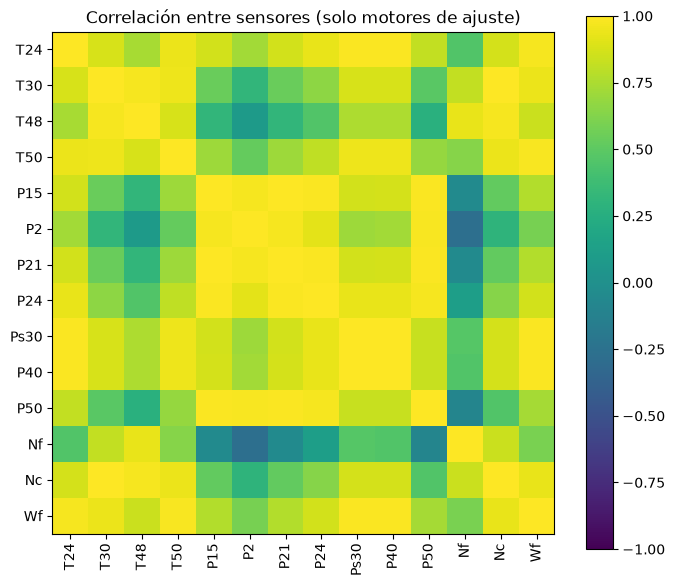

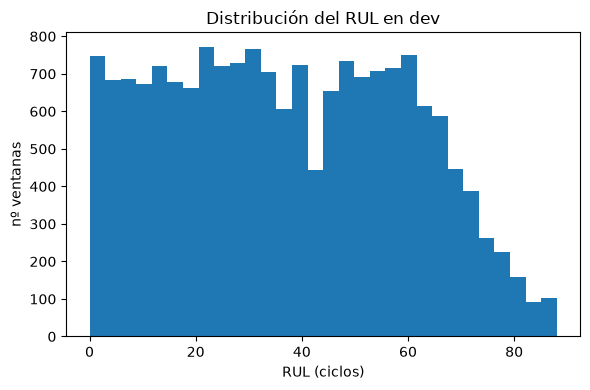

Ventanas dev: 17450 | RUL medio: 37.13 ciclos
Qué vemos: la correlación dice qué sensores se mueven juntos; el histograma, dónde se concentra el objetivo.


In [7]:
# EDA estilo clase (SOLO lectura: no ajusta nada, no re-entrena)
xs_fit = pd.DataFrame(raw["Xs_train"][fit_rows], columns=raw["sensor_names"])
corr = xs_fit.corr().round(2)
plt.figure(figsize=(7, 6))
plt.imshow(corr.values, vmin=-1, vmax=1)
plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)
plt.title("Correlación entre sensores (solo motores de ajuste)")
plt.colorbar()
plt.tight_layout(); plt.show()

plt.figure(figsize=(6, 4))
plt.hist(np.asarray(dev["y"]).ravel(), bins=30)
plt.xlabel("RUL (ciclos)"); plt.ylabel("nº ventanas")
plt.title("Distribución del RUL en dev")
plt.tight_layout(); plt.show()
print(f"Ventanas dev: {len(dev['y'])} | RUL medio: {float(np.mean(dev['y'])):.2f} ciclos")
print("Qué vemos: la correlación dice qué sensores se mueven juntos; el histograma, dónde se concentra el objetivo.")


## 4 · Modelo base A — LightGBM cuantílico

`objective='quantile', alpha=0.35` predice el percentil condicional 35, así que
el pronóstico puntual se inclina a *subestimar* la RUL.

**Se probó la mediana (0.50) y se rechazó en la lectura de test.** En `dev` fuera
de fold la mediana ganaba claramente (rama 9.11 → 8.18 de RMSE, híbrido 13.15 →
12.09, NASA −14,6 %), y aun así en test, con el mismo BiLSTM, cuesta 0.35 de RMSE
en el híbrido (4.24 → 4.59) y 2.0 en la rama (7.11 → 9.12). La razón es la misma
que explica el sesgo de vida alta: los motores de `dev` viven 63–89 ciclos y están
subestimados, los de test son más cortos, así que subir el cuantil arregla el
régimen que `dev` sobrerrepresenta y rompe el que test es. El barrido completo y
el acta están en `INFORME_p3_capacidad_vs_informacion.md` y en `ADR-007`.


In [8]:
t0 = time.time()
lgbm = make_lgbm(PRIMARY_SEED).fit(dev['X_tab'][fit_idx], dev['y'][fit_idx])
t_lgb = time.time() - t0

p_lgb_hold = lgbm.predict(dev['X_tab'][hold_idx])
p_lgb_test = lgbm.predict(test['X_tab'])
print(f'ajustado en {t_lgb:.2f} s | características {lgbm.n_features_in_}')

m = evaluate_predictions(test['y'], p_lgb_test, 'LightGBM quantile 0.35 (standalone)')
print(m)


ajustado en 0.58 s | características 93
{'Modelo': 'LightGBM quantile 0.35 (standalone)', 'RMSE': 7.113, 'MAE': 5.585, 'R2': 0.8551, 'NASA_Score': 5794.9}


**Fijate (estilo clase):** el baseline se equivoca mucho mas que el LightGBM. Cualquier modelo util tiene que ganarle.
Si `MAE train << MAE val`, memoriza. Aqui el LightGBM cuantilico esta sesgado a subestimar a proposito (`alpha=0.35`).


Baseline media train = 38.08 ciclos


,Modelo,RMSE,MAE,R2,NASA_Score
0,LightGBM cuantil 0.35,7.113,5.585,0.855,5794.9
1,Baseline (media train),20.022,17.059,-0.148,48840.3


top-5 rasgos: ['f21', 'f10', 'f11', 'f12', 'f0']


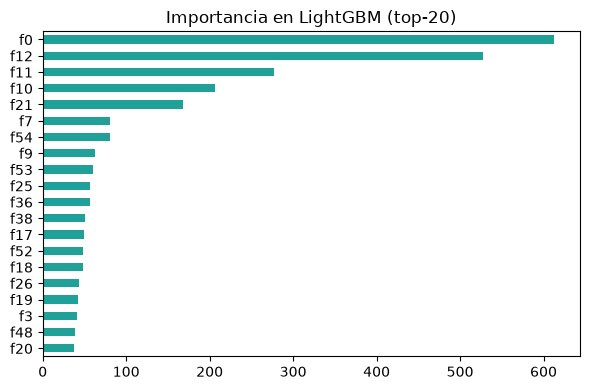

In [9]:
# Fase A — baseline tonto + importancia LGBM (SOLO lectura, no entra en la eleccion)
# Baseline: predecir siempre la media del train (motores de ajuste). Referencia pedagogica, como en clase.
baseline_val = float(dev["y"][fit_idx].mean())
pred_media = np.full_like(test["y"], baseline_val, dtype=float)
fila_base = evaluar_clase("Baseline (media train)", test["y"], pred_media)
print(f"Baseline media train = {baseline_val:.2f} ciclos")
mostrar_clase([fila_base,
               evaluar_clase("LightGBM cuantil 0.35", test["y"], p_lgb_test)])

# Importancia LGBM (solo lectura, como plantilla cell 60)
imp = pd.Series(np.asarray(lgbm.feature_importances_, dtype=float),
                index=[f"f{i}" for i in range(lgbm.n_features_in_)]).sort_values()
print(f"top-5 rasgos: {imp.tail(5).index.tolist()}")
imp.tail(20).plot.barh(figsize=(6, 4), title="Importancia en LightGBM (top-20)", color="#1FA098")
plt.tight_layout(); plt.show()


## 5 · Modelo base B — BiLSTM con triple pooling temporal

19 canales, dos capas LSTM bidireccionales de 64 unidades y una cabeza que
concatena el último paso, la media y el máximo: el estado actual, el nivel de la
trayectoria y el transitorio extremo. Se valida en el motor 16, que nunca entra
en el ajuste.


In [10]:
model = build_champion_bilstm(input_shape=dev['X_seq'].shape[1:], dense_units=32, seed=PRIMARY_SEED)
model.summary()
print()
print('parámetros:', model.count_params())


Model: "BiLSTM_TriplePooling_RUL"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_window        │ (None, 50, 19)    │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ batch_norm_input    │ (None, 50, 19)    │         76 │ input_window[0][… │
│ (BatchNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_1      │ (None, 50, 128)   │     43,008 │ batch_norm_input… │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_1 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_1[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bilstm_layer_2      │ (None, 50, 128)   │     98,816 │ dropout_1[0][0]   │
│ (Bidirectional)     │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_2 (Dropout) │ (None, 50, 128)   │          0 │ bilstm_layer_2[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ last_step           │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (LastStepPooling)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_avg_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_max_pool     │ (None, 128)       │          0 │ dropout_2[0][0]   │
│ (GlobalMaxPooling1… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ temporal_pooling    │ (None, 384)       │          0 │ last_step[0][0],  │
│ (Concatenate)       │                   │            │ global_avg_pool[… │
│                     │                   │            │ global_max_pool[… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_pooled      │ (None, 384)       │          0 │ temporal_pooling… │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_proj (Dense)  │ (None, 32)        │     12,320 │ dropout_pooled[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rul_output (Dense)  │ (None, 1)         │         33 │ dense_proj[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 154,253 (602.55 KB)

 Trainable params: 154,215 (602.40 KB)

 Non-trainable params: 38 (152.00 B)


parámetros: 154253


In [11]:
t0 = time.time()
result = run_seed(raw, seed=PRIMARY_SEED, fit_units=FIT_UNITS, holdout_units=HOLDOUT_UNITS,
                  test_units=TEST_UNITS, window=WINDOW_SIZE, step_train=STEP_TRAIN,
                  step_test=STEP_TEST, epochs=22)
print(f'LightGBM {result["t_lgb"]:.2f} s | BiLSTM {result["t_lstm"]:.1f} s')

hist = result['history'].history
print('épocas ejecutadas:', len(hist['loss']))
print('mejor val_loss:', round(float(min(hist['val_loss'])), 3))

m = evaluate_predictions(result['test']['y'], result['p_lstm_test'],
                         'BiLSTM triple pooling (standalone)')
print(m)


LightGBM 0.53 s | BiLSTM 141.8 s
épocas ejecutadas: 14
mejor val_loss: 8.297
{'Modelo': 'BiLSTM triple pooling (standalone)', 'RMSE': 5.651, 'MAE': 4.352, 'R2': 0.9085, 'NASA_Score': 3818.9}


In [12]:
# Puente NB1 -> NB2: guarda intermedios (no cambia ningun calculo del original)
import pathlib, joblib, numpy as np
ART = _ROOT / "notebooks" / "ds02_ensemble" / "artifacts"
ART.mkdir(parents=True, exist_ok=True)
# dev/test contienen arrays + meta (DataFrame). Se guardan por separado para no picklear el modelo keras.
np.savez_compressed(ART / "nb1_dev.npz",
    X_seq=dev["X_seq"], X_tab=dev["X_tab"], y=dev["y"],
    X_raw=dev["X_raw"],
    meta_unit=dev["meta"]["unit"].values, meta_cycle=dev["meta"]["cycle"].values)
np.savez_compressed(ART / "nb1_test.npz",
    X_seq=test["X_seq"], X_tab=test["X_tab"], y=test["y"],
    X_raw=test["X_raw"],
    meta_unit=test["meta"]["unit"].values, meta_cycle=test["meta"]["cycle"].values)
joblib.dump({"prep": prep, "fit_idx": fit_idx, "hold_idx": hold_idx,
             "dev_units": dev_units, "lgbm": lgbm,
             "p_lgb_hold": p_lgb_hold, "p_lgb_test": p_lgb_test},
            ART / "nb1_aux.joblib")
joblib.dump({"p_lstm_hold": result["p_lstm_hold"], "p_lstm_test": result["p_lstm_test"],
             "p_lgb_hold": result["p_lgb_hold"], "p_lgb_test": result["p_lgb_test"],
             "t_lgb": result["t_lgb"], "t_lstm": result["t_lstm"],
             "history": result["history"].history},
            ART / "nb1_result_arrays.joblib")
result["bilstm"].save(ART / "bilstm_seed42.keras")
print("[NB1 OK] artefactos en", ART.resolve())
print("siguiente: abrir 02_decision_ablacion_oof_ensamble.ipynb")


[NB1 OK] artefactos en C:\Users\mikel\Desktop\Pruebas\nasa\notebooks\ds02_ensemble\artifacts
siguiente: abrir 02_decision_ablacion_oof_ensamble.ipynb
